# Testing: Instance Segmentation Panoptic Indoor v5

NRP berakhiran 036, digit terakhir 6 (rentang 6–7), variabel eksperimen: augmentasi (tanpa / default / rancangan sendiri).

| Model | Keluarga |
|---|---|
| YOLO11s-seg | One-stage CNN |
| YOLOv8s-seg | One-stage CNN |
| Mask R-CNN R50-FPN v2 | Two-stage CNN |

## 0. Konfigurasi

In [1]:
TRAIN_OUTPUT = "auto"

RF_WORKSPACE, RF_PROJECT, RF_VERSION = "panopticindoor", "panoptic-indoor-segmentation", 5
TEST_WORKSPACE, TEST_PROJECT, TEST_VERSION = "ghazanfar-latief", "panoptic-indoor-segmentation-rlrwm", 2
HP_COUNT = 44
HAS_OWN = True

PHOTO_DIR = "/kaggle/input/foto-asli-hp"
DRIVE_PHOTOS = "https://drive.google.com/drive/folders/1TTgtsx8MvveuMMwQ_LW-rigMk9M8pWVd"
FAIL_IMAGES = []

# Label di anotasi HP yang namanya beda dengan kelas dataset latih
HP_MERGE = {"floor": "floor-other-merged"}

MERGE = {
    "ligjt": "light", "liht": "light", "llight": "light",
    "persob": "person",
    "spon": "spoon", "spoom": "spoon",
    "cuo": "cup", "cyo": "cup",
    "palte": "plate",
    "pap": "paper", "paper-merged": "paper",
    "staris": "stairs",
    "stovv": "stove-merged",
    "towl": "towel",
    "scissor": "scissors",
    "phone": "cell phone",
    "ruf": "rug-merged",
    "windo": "window-other",
}
DROP = []

IMGSZ = 640

## 1. Setup

In [2]:
import os, glob, json, yaml, shutil, time, datetime, csv, collections, traceback, contextlib, io
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
assert os.path.exists("/kaggle/working"), "Notebook ini khusus Kaggle."

!pip install -q roboflow ultralytics pycocotools pillow-heif gdown
!pip uninstall -y -q albumentations

import numpy as np, pandas as pd, torch
from kaggle_secrets import UserSecretsClient

ROOT = "/kaggle/working/CV_Testing"
DATA = "/tmp/data"
RUNS = f"{ROOT}/runs"
os.makedirs(RUNS, exist_ok=True)

if TRAIN_OUTPUT == "auto":
    cands = glob.glob("/kaggle/input/**/CV_InstanceSeg", recursive=True)
    TRAIN_OUTPUT = max(cands, key=lambda d: len(glob.glob(f"{d}/runs/*/DONE")), default="")
TR = f"{TRAIN_OUTPUT}/CV_InstanceSeg" if os.path.isdir(f"{TRAIN_OUTPUT}/CV_InstanceSeg") else TRAIN_OUTPUT
assert os.path.isdir(f"{TR}/runs"), f"Tidak ada folder runs di {TR}. Tambahkan output notebook training lewat Add Input."
if os.path.exists(f"{TR}/train_config.json"):
    cfg = json.load(open(f"{TR}/train_config.json"))
    MERGE, DROP, IMGSZ = cfg["MERGE"], cfg["DROP"], cfg["IMGSZ"]
    print("MERGE/DROP/IMGSZ diambil dari train_config.json")
print("Model dari", TR, "->", sorted(os.listdir(f"{TR}/runs")))

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (lebih lambat, tanpa antre GPU)")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
MERGE/DROP/IMGSZ diambil dari train_config.json
Model dari /kaggle/input/notebooks/apasijann/train-instance-seg/CV_InstanceSeg -> ['aug_custom', 'aug_default', 'aug_none', 'mask_rcnn_aug_custom', 'mask_rcnn_aug_none', 'mask_rcnn_r50', 'val', 'yolo11s_aug_custom', 'yolo11s_aug_none', 'yolo11s_seg', 'yolov8s_aug_custom', 'yolov8s_aug_none', 'yolov8s_seg']
Device: Tesla T4


## 2. Fungsi bantu

In [3]:
ERR_LOG = f"{ROOT}/errors.txt"
GPU_LOG = f"{ROOT}/gpu_time_log.csv"

def stage(name, fn, *args, **kw):
    try:
        return fn(*args, **kw)
    except Exception:
        tb = traceback.format_exc()
        print(f"!!! Tahap {name} gagal:\n{tb}")
        with open(ERR_LOG, "a") as f:
            f.write(f"== {name} ({datetime.datetime.now():%Y-%m-%d %H:%M}) ==\n{tb}\n")
        return None

@contextlib.contextmanager
def gpu_timer(run_name):
    start = time.time()
    try:
        yield
    finally:
        mins = (time.time() - start) / 60
        new = not os.path.exists(GPU_LOG)
        with open(GPU_LOG, "a", newline="") as f:
            w = csv.writer(f)
            if new:
                w.writerow(["run", "gpu", "start", "minutes"])
            gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
            w.writerow([run_name, gpu, datetime.datetime.fromtimestamp(start).isoformat(timespec="seconds"), round(mins, 1)])
        print(f"[{run_name}] {mins:.1f} menit GPU")

def load_names(yaml_path):
    n = yaml.safe_load(open(yaml_path))["names"]
    return list(n.values()) if isinstance(n, dict) else list(n)

def label_counts(root, names, split="*"):
    cnt = collections.Counter()
    for f in glob.glob(f"{root}/{split}/labels/*.txt"):
        cnt.update(names[int(l.split()[0])] for l in open(f) if l.strip())
    return cnt

def class_table(root, names):
    return (pd.DataFrame({s: label_counts(root, names, s) for s in ["train", "valid", "test"]})
              .fillna(0).astype(int).sort_values("train", ascending=False))

def write_yaml(path, root, names, train="train/images", val="valid/images", test="test/images"):
    yaml.safe_dump({"path": root, "train": train, "val": val, "test": test,
                    "names": dict(enumerate(names))}, open(path, "w"))

def merge_yolo(root, merge, drop):
    old = load_names(f"{root}/data.yaml")
    new_names = sorted({merge.get(n, n) for n in old} - set(drop))
    idx = {i: new_names.index(merge.get(n, n)) for i, n in enumerate(old) if merge.get(n, n) not in drop}
    before = label_counts(root, old)
    for lab in glob.glob(f"{root}/*/labels/*.txt"):
        rows = [l.split() for l in open(lab) if l.strip()]
        with open(lab, "w") as f:
            f.writelines(" ".join([str(idx[int(r[0])])] + r[1:]) + "\n" for r in rows if int(r[0]) in idx)
    d = yaml.safe_load(open(f"{root}/data.yaml"))
    d["names"], d["nc"] = new_names, len(new_names)
    yaml.safe_dump(d, open(f"{root}/data.yaml", "w"))
    expect = collections.Counter()
    for n, c in before.items():
        if merge.get(n, n) not in drop:
            expect[merge.get(n, n)] += c
    assert label_counts(root, new_names) == expect, "Merge kelas YOLO tidak konsisten!"
    return new_names

def merge_coco(root, merge, drop, names):
    cats = [{"id": i + 1, "name": n, "supercategory": "none"} for i, n in enumerate(names)]
    by_name = {c["name"]: c["id"] for c in cats}
    for p in glob.glob(f"{root}/*/_annotations.coco.json"):
        d = json.load(open(p))
        id2new = {c["id"]: merge.get(c["name"], c["name"]) for c in d["categories"]}
        d["annotations"] = [{**a, "category_id": by_name[id2new[a["category_id"]]]}
                            for a in d["annotations"] if id2new[a["category_id"]] not in drop]
        d["categories"] = cats
        json.dump(d, open(p, "w"))

def keep_hp_only(yolo_root, coco_root, v5_root, expected):
    assert expected, "Isi HP_COUNT dengan jumlah foto HP di konfigurasi."
    base = lambda p: os.path.basename(p).split(".rf.")[0]
    v5 = {base(p) for p in glob.glob(f"{v5_root}/*/images/*")}
    kept = set()
    for img in glob.glob(f"{yolo_root}/*/images/*"):
        if base(img) in v5:
            lab = f"{os.path.dirname(os.path.dirname(img))}/labels/{os.path.splitext(os.path.basename(img))[0]}.txt"
            os.remove(img)
            if os.path.exists(lab):
                os.remove(lab)
        else:
            kept.add(base(img))
    assert len(kept) == expected, f"Foto HP terdeteksi {len(kept)}, HP_COUNT {expected}. Cek versi Roboflow."
    for p in glob.glob(f"{coco_root}/*/_annotations.coco.json"):
        d = json.load(open(p))
        drop = {im["id"] for im in d["images"] if base(im["file_name"]) in v5}
        for im in d["images"]:
            if im["id"] in drop:
                os.remove(f"{os.path.dirname(p)}/{im['file_name']}")
        d["images"] = [im for im in d["images"] if im["id"] not in drop]
        d["annotations"] = [a for a in d["annotations"] if a["image_id"] not in drop]
        json.dump(d, open(p, "w"))
    n_coco = sum(len(json.load(open(p))["images"]) for p in glob.glob(f"{coco_root}/*/_annotations.coco.json"))
    assert n_coco == expected, f"Foto HP di COCO {n_coco}, HP_COUNT {expected}."
    print(f"Test set HP: {len(kept)} foto, gambar dataset asli dibuang.")

def norm_stem(name):
    import re
    stem = os.path.basename(name).split(".rf.")[0]
    stem = re.sub(r"[._](jpe?g|png|heic|heif)$", "", stem, flags=re.I)
    return re.sub(r"[^0-9a-z]", "", stem.lower())

def get_originals():
    # Foto asli dari HP (masih punya tag EXIF): dari Kaggle dataset PHOTO_DIR, atau unduh dari DRIVE_PHOTOS.
    if glob.glob(f"{PHOTO_DIR}/**/*.*", recursive=True):
        return PHOTO_DIR
    dst = "/tmp/foto_hp"
    if not glob.glob(f"{dst}/**/*.*", recursive=True) and DRIVE_PHOTOS:
        import gdown
        gdown.download_folder(url=DRIVE_PHOTOS, output=dst, quiet=True, remaining_ok=True)
    return dst

def fix_orientation(yolo_root, coco_root, orig_dir):
    # Roboflow (tanpa Auto-Orient) membuang tag EXIF tapi tidak memutar piksel, sedangkan anotasi dibuat
    # pada gambar tegak. Arah putar diambil dari tag EXIF foto asli, lalu dicek dengan ukuran di anotasi.
    from PIL import Image
    T = Image.Transpose
    ops = {2: [T.FLIP_LEFT_RIGHT], 3: [T.ROTATE_180], 4: [T.FLIP_TOP_BOTTOM], 5: [T.TRANSPOSE],
           6: [T.ROTATE_270], 7: [T.TRANSVERSE], 8: [T.ROTATE_90]}
    orient = {}
    for q in glob.glob(f"{orig_dir}/**/*.*", recursive=True):
        try:
            orient[norm_stem(q)] = Image.open(q).getexif().get(0x0112, 1)
        except Exception:
            pass
    base = lambda q: os.path.basename(q).split(".rf.")[0]
    size = {}
    for q in glob.glob(f"{coco_root}/*/_annotations.coco.json"):
        for im in json.load(open(q))["images"]:
            size[base(im["file_name"])] = (im["width"], im["height"])
    files = glob.glob(f"{yolo_root}/*/images/*") + [q for q in glob.glob(f"{coco_root}/*/*") if not q.endswith(".json")]
    stats = collections.Counter()
    for q in files:
        target = size.get(base(q))
        if target is None:
            continue
        im = Image.open(q)
        o = im.getexif().get(0x0112, 1)
        if o == 1:
            o = orient.get(norm_stem(q), 1)
        out = im
        for op in ops.get(o, []):
            out = out.transpose(op)
        if out.size != target and im.size == target:
            out = im
        if out.size != target:
            stats["ukuran tidak cocok"] += 1
            continue
        stats["diputar" if out is not im else "sudah tegak"] += 1
        out.convert("RGB").save(q, quality=95)
    print("Orientasi foto HP:", dict(stats), f"| {len(orient)} foto asli dibaca dari {orig_dir}")
    assert not stats["ukuran tidak cocok"], "Ada foto yang ukurannya tidak cocok dengan anotasi."

def downscale_hp(yolo_root, coco_root, max_side=1280):
    # Foto HP 12 MP membuat Mask R-CNN menempel mask berukuran 4000x3000 per deteksi (CUDA out of memory).
    # Model tetap melihat input 640 px, jadi gambar dan anotasi diperkecil ke sisi terpanjang max_side.
    from PIL import Image
    n = 0
    for p in glob.glob(f"{coco_root}/*/_annotations.coco.json"):
        d = json.load(open(p))
        folder = os.path.dirname(p)
        by_img = collections.defaultdict(list)
        for a in d["annotations"]:
            by_img[a["image_id"]].append(a)
        for im in d["images"]:
            f = max_side / max(im["width"], im["height"])
            if f >= 1:
                continue
            w, h = round(im["width"] * f), round(im["height"] * f)
            Image.open(f"{folder}/{im['file_name']}").convert("RGB").resize((w, h), Image.LANCZOS).save(f"{folder}/{im['file_name']}", quality=95)
            for a in by_img[im["id"]]:
                a["bbox"] = [v * f for v in a["bbox"]]
                a["area"] = a["area"] * f * f
                if isinstance(a.get("segmentation"), list):
                    a["segmentation"] = [[v * f for v in poly] for poly in a["segmentation"]]
            im["width"], im["height"] = w, h
            n += 1
        json.dump(d, open(p, "w"))
    for q in glob.glob(f"{yolo_root}/*/images/*"):
        im = Image.open(q)
        f = max_side / max(im.size)
        if f < 1:
            im.convert("RGB").resize((round(im.width * f), round(im.height * f)), Image.LANCZOS).save(q, quality=95)
    print(f"{n} foto HP diperkecil ke sisi terpanjang {max_side} px")

def remap_yolo(src_root, dst_root, train_names):
    src_names = load_names(f"{src_root}/data.yaml")
    unknown = sorted(set(label_counts(src_root, src_names)) - set(train_names))
    assert not unknown, f"Kelas di test set HP tidak ada di data latih: {unknown}"
    idx = {i: train_names.index(n) for i, n in enumerate(src_names) if n in train_names}
    shutil.rmtree(dst_root, ignore_errors=True)
    os.makedirs(f"{dst_root}/test/images"); os.makedirs(f"{dst_root}/test/labels")
    for split in ["train", "valid", "test"]:
        for img in glob.glob(f"{src_root}/{split}/images/*"):
            shutil.copy(img, f"{dst_root}/test/images/")
        for lab in glob.glob(f"{src_root}/{split}/labels/*.txt"):
            rows = [l.split() for l in open(lab) if l.strip()]
            with open(f"{dst_root}/test/labels/{os.path.basename(lab)}", "w") as f:
                f.writelines(" ".join([str(idx[int(r[0])])] + r[1:]) + "\n" for r in rows)
    assert label_counts(src_root, src_names) == label_counts(dst_root, train_names), "Remap kelas tidak konsisten!"

def merge_remap_coco(src_root, train_json, dst_json):
    cats = json.load(open(train_json))["categories"]
    by_name = {c["name"]: c["id"] for c in cats}
    out = {"info": {}, "images": [], "annotations": [], "categories": cats}
    n_src = 0
    for split in ["train", "valid", "test"]:
        p = f"{src_root}/{split}/_annotations.coco.json"
        if not os.path.exists(p):
            continue
        d = json.load(open(p))
        id2name = {c["id"]: c["name"] for c in d["categories"]}
        img_map = {}
        for im in d["images"]:
            img_map[im["id"]] = len(out["images"]) + 1
            out["images"].append({**im, "id": img_map[im["id"]], "file_name": f"{split}/{im['file_name']}"})
        for a in d["annotations"]:
            out["annotations"].append({**a, "id": len(out["annotations"]) + 1,
                                       "image_id": img_map[a["image_id"]],
                                       "category_id": by_name[id2name[a["category_id"]]]})
        n_src += len(d["annotations"])
    assert len(out["annotations"]) == n_src
    json.dump(out, open(dst_json, "w"))

## 3. Dataset: test set asli dan test set HP

In [4]:
from roboflow import Roboflow
rf = Roboflow(api_key=UserSecretsClient().get_secret("ROBOFLOW_API_KEY"))

ver = rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION)
ds_yolo = ver.download("yolov8", location=f"{DATA}/train_yolo", overwrite=True)
ds_coco = ver.download("coco",   location=f"{DATA}/train_coco", overwrite=True)
C = ds_coco.location

NAMES = merge_yolo(ds_yolo.location, MERGE, DROP)
merge_coco(C, MERGE, DROP, NAMES)
TRAIN_YAML = f"{ds_yolo.location}/data_abs.yaml"
write_yaml(TRAIN_YAML, ds_yolo.location, NAMES)

from ultralytics import YOLO

def best_yolo(name):
    p = f"{TR}/runs/{name}/weights/best.pt"
    return p if os.path.exists(p) else None

def best_mrcnn(name):
    p = f"{TR}/runs/{name}/best.pt"
    return p if os.path.exists(p) else None

CONDS = ["Tanpa augmentasi", "Default", "Rancangan sendiri"]
YOLO_MAIN = {"YOLO11s-seg": best_yolo("yolo11s_seg"), "YOLOv8s-seg": best_yolo("yolov8s_seg")}
MRCNN = best_mrcnn("mask_rcnn_r50")
AUG_EXP = {
    "YOLO11s-seg": dict(zip(CONDS, [best_yolo("yolo11s_aug_none"), YOLO_MAIN["YOLO11s-seg"], best_yolo("yolo11s_aug_custom")])),
    "YOLOv8s-seg": dict(zip(CONDS, [best_yolo("yolov8s_aug_none"), YOLO_MAIN["YOLOv8s-seg"], best_yolo("yolov8s_aug_custom")])),
    "Mask R-CNN R50-FPN v2": dict(zip(CONDS, [best_mrcnn("mask_rcnn_aug_none"), MRCNN, best_mrcnn("mask_rcnn_aug_custom")])),
    "YOLO11n-seg (pilot)": dict(zip(CONDS, [best_yolo("aug_none"), best_yolo("aug_default"), best_yolo("aug_custom")])),
}
for m, runs in AUG_EXP.items():
    print(f"{m}: " + ", ".join(f"{c} {'ada' if w else 'BELUM ADA'}" for c, w in runs.items()))

ref = next(w for w in YOLO_MAIN.values() if w)
assert list(YOLO(ref).names.values()) == NAMES, "Kelas hasil merge beda dengan kelas model. Samakan MERGE/DROP dengan notebook training."
print(len(NAMES), "kelas, cocok dengan model")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /tmp/data/train_yolo in yolov8:: 100%|██████████| 1856/1856 [00:00<00:00, 6249.75it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings



Extracting Dataset Version Zip to /tmp/data/train_coco in coco:: 100%|██████████| 930/930 [00:00<00:00, 4523.98it/s]


YOLO11s-seg: Tanpa augmentasi ada, Default ada, Rancangan sendiri ada
YOLOv8s-seg: Tanpa augmentasi ada, Default ada, Rancangan sendiri ada
Mask R-CNN R50-FPN v2: Tanpa augmentasi ada, Default ada, Rancangan sendiri ada
YOLO11n-seg (pilot): Tanpa augmentasi ada, Default ada, Rancangan sendiri ada
72 kelas, cocok dengan model


In [5]:
OWN_ROOT = f"{DATA}/own_remap"
OWN_YAML = f"{OWN_ROOT}/data_abs.yaml"
if HAS_OWN:
    tv = rf.workspace(TEST_WORKSPACE).project(TEST_PROJECT).version(TEST_VERSION)
    own_yolo = tv.download("yolov8", location=f"{DATA}/own_yolo", overwrite=True)
    own_coco = tv.download("coco",   location=f"{DATA}/own_coco", overwrite=True)

    keep_hp_only(own_yolo.location, own_coco.location, ds_yolo.location, HP_COUNT)
    ORIG_DIR = get_originals()
    fix_orientation(own_yolo.location, own_coco.location, ORIG_DIR)
    downscale_hp(own_yolo.location, own_coco.location)
    own_names = merge_yolo(own_yolo.location, {**MERGE, **HP_MERGE}, DROP)
    merge_coco(own_coco.location, {**MERGE, **HP_MERGE}, DROP, own_names)
    remap_yolo(own_yolo.location, OWN_ROOT, NAMES)
    write_yaml(OWN_YAML, OWN_ROOT, NAMES, train="test/images", val="test/images")
    OWN_COCO_JSON = f"{own_coco.location}/own_remap.coco.json"
    merge_remap_coco(own_coco.location, f"{C}/train/_annotations.coco.json", OWN_COCO_JSON)

    own_cnt = label_counts(OWN_ROOT, NAMES)
    print(sum(own_cnt.values()), "objek di test set HP")
    own_df = pd.Series(own_cnt, name="objek").sort_values(ascending=False)
    own_df.to_csv(f"{ROOT}/class_counts_hp.csv"); display(own_df)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /tmp/data/own_yolo in yolov8:: 100%|██████████| 1937/1937 [00:00<00:00, 5305.35it/s]


Extracting Dataset Version Zip to /tmp/data/own_coco in coco:: 100%|██████████| 971/971 [00:00<00:00, 3737.29it/s]


Test set HP: 44 foto, gambar dataset asli dibuang.
Orientasi foto HP: {'diputar': 86, 'sudah tegak': 2} | 47 foto asli dibaca dari /tmp/foto_hp
44 foto HP diperkecil ke sisi terpanjang 1280 px
679 objek di test set HP


wall-other-merged     71
chair                 61
window-other          55
floor-other-merged    53
light                 47
table-merged          32
person                29
ceiling-merged        24
wall-tile             23
wall                  21
plug                  20
wall-brick            19
window-blind          15
vase                  14
backpack              12
wall-wood             12
bottle                11
mirror-stuff          10
laptop                10
potted plant          10
toilet                 9
cabinet-merged         8
sink                   8
bowl                   8
cell phone             8
door-stuff             7
food-other-merged      7
stairs                 7
cardboard              6
dining table           6
flower                 6
spoon                  5
plate                  5
fork                   4
pillow                 4
trash-bin              4
floor-wood             4
cup                    4
tv                     3
toothbrush             3


## 4. Mask R-CNN

In [6]:
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
import torchvision.transforms.functional as TF
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_util
from PIL import Image

NUM_CLASSES = len(NAMES) + 1

class CocoSeg(Dataset):
    def __init__(self, json_path, img_root, train=False, aug="default"):
        with contextlib.redirect_stdout(io.StringIO()):
            self.coco = COCO(json_path)
        self.root, self.train, self.aug = img_root, train, aug
        self.ids = sorted(self.coco.imgs)
        if train:
            self.ids = [i for i in self.ids if self._anns(i)]

    def _anns(self, iid):
        return [a for a in self.coco.loadAnns(self.coco.getAnnIds(imgIds=iid))
                if a.get("segmentation") and a["bbox"][2] >= 1 and a["bbox"][3] >= 1]

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, k):
        iid = self.ids[k]
        info = self.coco.imgs[iid]
        img = TF.to_tensor(Image.open(f"{self.root}/{info['file_name']}").convert("RGB"))
        H, W = img.shape[-2:]
        anns = self._anns(iid)
        boxes = torch.tensor([[x, y, x + w, y + h] for x, y, w, h in (a["bbox"] for a in anns)],
                             dtype=torch.float32).reshape(-1, 4)
        masks = (torch.from_numpy(np.stack([self.coco.annToMask(a) for a in anns])) if anns
                 else torch.zeros((0, H, W), dtype=torch.uint8))
        labels = torch.tensor([a["category_id"] for a in anns], dtype=torch.int64)
        if self.train and self.aug != "none":
            img, masks, boxes, labels = augment(img, masks, boxes, labels, self.aug)
        return img, {"boxes": boxes, "labels": labels, "masks": masks, "image_id": iid}

def mask_boxes(masks):
    out = []
    for m in masks:
        ys, xs = torch.where(m > 0)
        out.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
    return torch.tensor(out, dtype=torch.float32).reshape(-1, 4)

def augment(img, masks, boxes, labels, mode):
    W = img.shape[-1]
    if torch.rand(1).item() < 0.5:
        img, masks = img.flip(-1), masks.flip(-1)
        boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
    if mode != "custom":
        return img, masks, boxes, labels
    u = lambda a, b: a + (b - a) * torch.rand(1).item()
    img = TF.adjust_brightness(img, u(0.4, 1.6))   # setara hsv_v=0.6
    img = TF.adjust_saturation(img, u(0.5, 1.5))   # setara hsv_s=0.5
    angle, shear = u(-15, 15), u(-5, 5)            # setara degrees=15, shear=5
    img = TF.affine(img, angle=angle, translate=[0, 0], scale=1.0, shear=[shear, 0.0]).clamp(0, 1)
    if len(masks):
        masks = (TF.affine(masks.float(), angle=angle, translate=[0, 0], scale=1.0, shear=[shear, 0.0],
                           interpolation=TF.InterpolationMode.NEAREST) > 0.5).to(torch.uint8)
        keep = masks.flatten(1).any(1)
        masks, labels = masks[keep], labels[keep]
        boxes = mask_boxes(masks)
    return img, masks, boxes, labels

def collate(batch):
    return tuple(zip(*batch))

def build_mrcnn(num_classes, pretrained=True):
    if pretrained:
        m = maskrcnn_resnet50_fpn_v2(weights="DEFAULT")
        m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, num_classes)
        m.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, num_classes)
    else:
        m = maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, num_classes=num_classes)
    return m.to(DEV)

def load_mrcnn(path):
    m = build_mrcnn(NUM_CLASSES, pretrained=False)
    m.load_state_dict(torch.load(path, map_location=DEV))
    return m

def to_rle(mask):
    rle = mask_util.encode(np.asfortranarray(mask.astype(np.uint8)))
    rle["counts"] = rle["counts"].decode()
    return rle

@torch.no_grad()
def mrcnn_preds(model, ds):
    model.eval()
    res = []
    for k in range(len(ds)):
        img, t = ds[k]
        out = model([img.to(DEV)])[0]
        for m, s, l in zip((out["masks"][:, 0] > 0.5).cpu().numpy(), out["scores"].tolist(), out["labels"].tolist()):
            res.append({"image_id": t["image_id"], "category_id": l, "segmentation": to_rle(m), "score": s})
    return res

def coco_eval_mrcnn(model, ds, quiet=False, per_class=None):
    res = mrcnn_preds(model, ds)
    if not res:
        return 0.0, 0.0
    with contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext():
        E = COCOeval(ds.coco, ds.coco.loadRes(res), "segm")
        E.evaluate(); E.accumulate(); E.summarize()
    if per_class is not None:
        prec = E.eval["precision"]
        for k, cid in enumerate(E.params.catIds):
            pk = prec[:, :, k, 0, -1]
            if (pk > -1).any():
                per_class[NAMES[cid - 1]] = float(pk[pk > -1].mean())
    return float(E.stats[0]), float(E.stats[1])

## 5. Evaluasi: test set asli vs test set HP

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,094,680 parameters, 0 gradients, 33.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1002.1±620.5 MB/s, size: 45.5 KB)
val: Scanning /tmp/data/train_yolo/test/labels... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 657.6it/s 0.5s
val: /tmp/data/train_yolo/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /tmp/data/train_yolo/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
val: New cache created: /tmp/data/train_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 2.8it/s 8.4s
                   all        359       5341      0.344      0.208       0.17       0.12      0.366      0.195      0.164        0.1
              back

,mAP50-95 asli,mAP50 asli,mAP50-95 HP,mAP50 HP,selisih mAP50-95,turun (%)
model,,,,,,
YOLO11s-seg,0.1004,0.1636,0.1225,0.1927,-0.0222,-22.1001
YOLOv8s-seg,0.1036,0.1636,0.1475,0.2205,-0.0440,-42.4406
Mask R-CNN R50-FPN v2,0.1015,0.1648,0.1076,0.1652,-0.0061,-5.9667


AP mask (mAP50-95) PER KELAS


,objek di test asli,objek di HP,YOLO11s-seg | asli,YOLO11s-seg | hp,YOLOv8s-seg | asli,YOLOv8s-seg | hp,Mask R-CNN R50-FPN v2 | asli,Mask R-CNN R50-FPN v2 | hp
food-other-merged,149.0,7.0,0.355,0.513,0.358,0.463,0.396,0.636
sink,30.0,8.0,0.155,0.485,0.105,0.325,0.133,0.481
pillow,37.0,4.0,0.034,0.328,0.053,0.107,0.027,0.477
bottle,58.0,11.0,0.155,0.288,0.162,0.497,0.269,0.462
trash-bin,4.0,4.0,0.020,0.223,0.100,0.659,0.019,0.459
...,...,...,...,...,...,...,...,...
teddy bear,6.0,0.0,0.000,NaN,0.000,NaN,0.000,NaN
toaster,4.0,0.0,0.000,NaN,0.000,NaN,0.000,NaN
towel,19.0,0.0,0.041,NaN,0.002,NaN,0.015,NaN
wall-stone,2.0,0.0,0.000,NaN,0.000,NaN,0.000,NaN


Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,094,680 parameters, 0 gradients, 33.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 594.0±435.9 MB/s, size: 23.0 KB)
val: Scanning /tmp/data/train_yolo/test/labels.cache... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 79.3Mit/s 0.0s
val: /tmp/data/train_yolo/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /tmp/data/train_yolo/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 2.5it/s 9.1s
                   all        359       5341      0.386      0.234      0.223       0.16      0.382      0.227      0.212      0.135
              backpack         15         31      0.491     0.0323      0.10

mAP50-95 asli  mAP50 asli  \
model                 kondisi                                        
YOLO11s-seg           Tanpa augmentasi          0.1352      0.2118   
                      Default                   0.1004      0.1636   
                      Rancangan sendiri         0.0976      0.1556   
YOLOv8s-seg           Tanpa augmentasi          0.1238      0.1925   
                      Default                   0.1036      0.1636   
                      Rancangan sendiri         0.0967      0.1558   
Mask R-CNN R50-FPN v2 Tanpa augmentasi          0.1015      0.1624   
                      Default                   0.1015      0.1648   
                      Rancangan sendiri         0.0944      0.1544   
YOLO11n-seg (pilot)   Tanpa augmentasi          0.0886      0.1437   
                      Default                   0.0891      0.1463   
                      Rancangan sendiri         0.0889      0.1436   

                                         mAP50-95 HP  mAP50 HP  \
model                 kondisi                                    
YOLO11s-seg           Tanpa augmentasi        0.1580    0.2123   
                      Default                 0.1225    0.1927   
                      Rancangan sendiri       0.1289    0.1870   
YOLOv8s-seg           Tanpa augmentasi        0.1541    0.2314   
                      Default                 0.1475    0.2205   
                      Rancangan sendiri       0.1165    0.1781   
Mask R-CNN R50-FPN v2 Tanpa augmentasi        0.1292    0.1917   
                      Default                 0.1076    0.1652   
                      Rancangan sendiri       0.1030    0.1525   
YOLO11n-seg (pilot)   Tanpa augmentasi        0.0799    0.1367   
                      Default                 0.1153    0.1704   
                      Rancangan sendiri       0.0962    0.1489   

                                         selisih mAP50-95  turun (%)  
model                 kondisi                                         
YOLO11s-seg           Tanpa augmentasi            -0.0228   -16.8461  
                      Default                     -0.0222   -22.1001  
                      Rancangan sendiri           -0.0313   -32.0211  
YOLOv8s-seg           Tanpa augmentasi            -0.0304   -24.5412  
                      Default                     -0.0440   -42.4406  
                      Rancangan sendiri           -0.0198   -20.4677  
Mask R-CNN R50-FPN v2 Tanpa augmentasi            -0.0278   -27.3741  
                      Default                     -0.0061    -5.9667  
                      Rancangan sendiri           -0.0086    -9.0724  
YOLO11n-seg (pilot)   Tanpa augmentasi             0.0088     9.8759  
                      Default                     -0.0262   -29.3800  
                      Rancangan sendiri           -0.0072    -8.1361

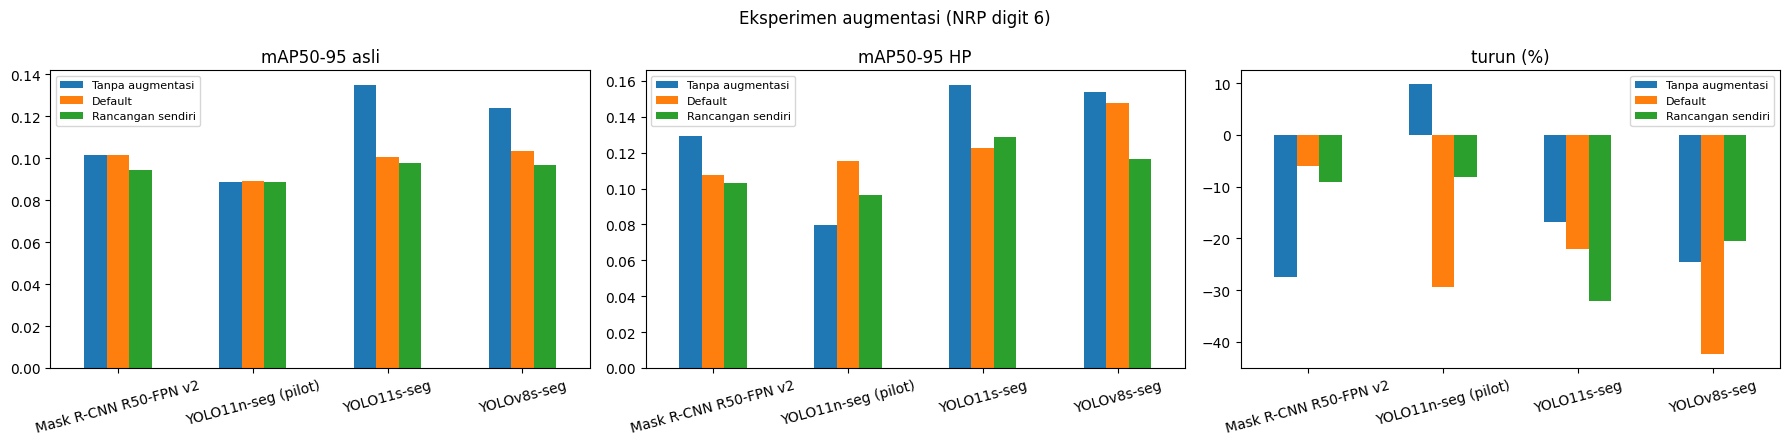

In [7]:
import functools
import matplotlib.pyplot as plt
NA = (float("nan"), float("nan"))
PER_CLASS = {}

def eval_yolo(weights, data_yaml, tag, imgsz=IMGSZ):
    m = YOLO(weights).val(data=data_yaml, split="test", imgsz=imgsz, device=DEVICE,
                          project=f"{RUNS}/val", name=tag, exist_ok=True)
    PER_CLASS[tag] = {NAMES[int(i)]: float(a) for i, a in zip(m.ap_class_index, m.seg.ap)}
    return m.seg.map, m.seg.map50

def eval_mrcnn(weights, json_path, img_root, tag):
    PER_CLASS[tag] = {}
    return coco_eval_mrcnn(load_mrcnn(weights), CocoSeg(json_path, img_root), per_class=PER_CLASS[tag])

def run_of(weights):
    return weights.split("/runs/")[-1].split("/")[0]

@functools.lru_cache(maxsize=None)
def score(weights, which):
    run = run_of(weights)
    if "mask_rcnn" in run:
        if which == "asli":
            return eval_mrcnn(weights, f"{C}/test/_annotations.coco.json", f"{C}/test", f"{run}_{which}")
        return eval_mrcnn(weights, OWN_COCO_JSON, own_coco.location, f"{run}_{which}")
    return eval_yolo(weights, TRAIN_YAML if which == "asli" else OWN_YAML, f"{run}_{which}")

def row(label, weights):
    if weights is None:
        print(f"[{' | '.join(label)}] model tidak ditemukan, dilewati"); return None
    a = stage(f"eval {label} asli", score, weights, "asli") or NA
    h = (stage(f"eval {label} HP", score, weights, "hp") or NA) if HAS_OWN else NA
    return (*label, *a, *h)

def domain_table(rows, idx):
    df = pd.DataFrame([r for r in rows if r],
                      columns=[*idx, "mAP50-95 asli", "mAP50 asli", "mAP50-95 HP", "mAP50 HP"]).set_index(idx)
    df["selisih mAP50-95"] = df["mAP50-95 asli"] - df["mAP50-95 HP"]
    df["turun (%)"] = 100 * df["selisih mAP50-95"] / df["mAP50-95 asli"]
    return df.round(4)

main_rows = [row((n,), w) for n, w in {**YOLO_MAIN, "Mask R-CNN R50-FPN v2": MRCNN}.items()]
main_df = domain_table(main_rows, ["model"]); main_df.to_csv(f"{ROOT}/hasil_model_utama.csv")
print("HASIL MODEL UTAMA (mask mAP)"); display(main_df)

MAIN = {**YOLO_MAIN, "Mask R-CNN R50-FPN v2": MRCNN}
SETS = ["asli", "hp"] if HAS_OWN else ["asli"]
ap_df = pd.DataFrame({f"{n} | {w_}": PER_CLASS.get(f"{run_of(w)}_{w_}", {}) for n, w in MAIN.items() if w for w_ in SETS})
ap_df.insert(0, "objek di test asli", pd.Series(label_counts(ds_yolo.location, NAMES, "test")))
if HAS_OWN:
    ap_df.insert(1, "objek di HP", pd.Series(label_counts(OWN_ROOT, NAMES)))
ap_df = ap_df.fillna({"objek di test asli": 0, "objek di HP": 0}).sort_values(ap_df.columns[-1], ascending=False).round(3)
ap_df.to_csv(f"{ROOT}/ap_per_kelas.csv")
print("AP mask (mAP50-95) PER KELAS"); display(ap_df)

def ap_kelas(nama):
    return ap_df.loc[nama]

aug_rows = [row((m, c), w) for m, runs in AUG_EXP.items() for c, w in runs.items()]
aug_df = domain_table(aug_rows, ["model", "kondisi"]); aug_df.to_csv(f"{ROOT}/hasil_eksperimen_augmentasi.csv")
print("EKSPERIMEN AUGMENTASI"); display(aug_df)

cols = ["mAP50-95 asli", "mAP50-95 HP", "turun (%)"] if HAS_OWN else ["mAP50-95 asli"]
fig, axes = plt.subplots(1, len(cols), figsize=(6 * len(cols), 4.5), squeeze=False)
for ax, col in zip(axes[0], cols):
    aug_df[col].unstack("kondisi").reindex(columns=CONDS).plot.bar(ax=ax, rot=15)
    ax.set_title(col); ax.set_xlabel(""); ax.legend(fontsize=8)
plt.suptitle("Eksperimen augmentasi (NRP digit 6)")
plt.tight_layout(); plt.savefig(f"{ROOT}/grafik_eksperimen_augmentasi.png", dpi=120); plt.show()

## 6. Analisis kegagalan

Results saved to /kaggle/working/CV_Testing/prediksi_hp/YOLO11s-seg
Results saved to /kaggle/working/CV_Testing/prediksi_hp/YOLOv8s-seg
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.06s)
creating index...
index created!
AP mask per foto HP (terendah di atas). Foto gagal yang dipilih: ['20261123_165114_jpg.rf.0c01b6026aa5c91b966c15383c8244a6.jpg', '20261122_143914_jpg.rf.006ef7d15e80654872b15e69c47b7d54.jpg', '20261122_144020_jpg.rf.c3573c6047795d24b4a20b5f4f8ba9fc.jpg', '20261118_140402_jpg.rf.858d9933e3c4cd8ce3f7457f2631579d.jpg', '20261123_144356_jpg.rf.889164867b709aaa571bcd44077bc1a6.jpg']


,YOLO11s-seg,YOLOv8s-seg,Mask R-CNN,rata-rata,objek GT,kelas GT
20261123_165114_jpg.rf.0c01b6026aa5c91b966c15383c8244a6.jpg,0.000,0.000,0.000,0.000,3,"door-stuff, toilet, wall-other-merged"
20261122_143914_jpg.rf.006ef7d15e80654872b15e69c47b7d54.jpg,0.000,0.000,0.000,0.000,4,"floor-other-merged, toilet, wall-other-merged"
20261123_142844_jpg.rf.b0ccf6e7635b1f367e4d0ef86207685f.jpg,0.000,0.000,0.000,0.000,2,"floor-other-merged, wall-tile"
20261122_144020_jpg.rf.c3573c6047795d24b4a20b5f4f8ba9fc.jpg,0.000,0.000,0.026,0.009,7,"ceiling-merged, light, wall-other-merged"
20261118_140402_jpg.rf.858d9933e3c4cd8ce3f7457f2631579d.jpg,0.000,0.020,0.040,0.020,6,"floor-other-merged, potted plant, toilet, vase..."
20261123_144356_jpg.rf.889164867b709aaa571bcd44077bc1a6.jpg,0.006,0.017,0.079,0.034,22,"chair, table-merged, wall-other-merged, window..."
20261123_172634_jpg.rf.609c3ce79c6c238611f1d38a95b34a41.jpg,0.000,0.074,0.051,0.042,15,"backpack, cardboard, ceiling-merged, table-mer..."
20261121_092205_jpg.rf.faab9f1a9dd462784e3758cc3724c75a.jpg,0.032,0.101,0.000,0.044,7,"floor-other-merged, toilet, toothbrush, wall-tile"
20261122_165731_jpg.rf.a4ebf665340998534aabb1e60c55c675.jpg,0.031,0.009,0.092,0.044,21,"bowl, chair, fork, spoon, table-merged, wall-o..."
20261123_155719_jpg.rf.1681a16177d5e95b1e609e557966e272.jpg,0.099,0.079,0.020,0.066,34,"chair, flower, vase, wall-other-merged, window..."


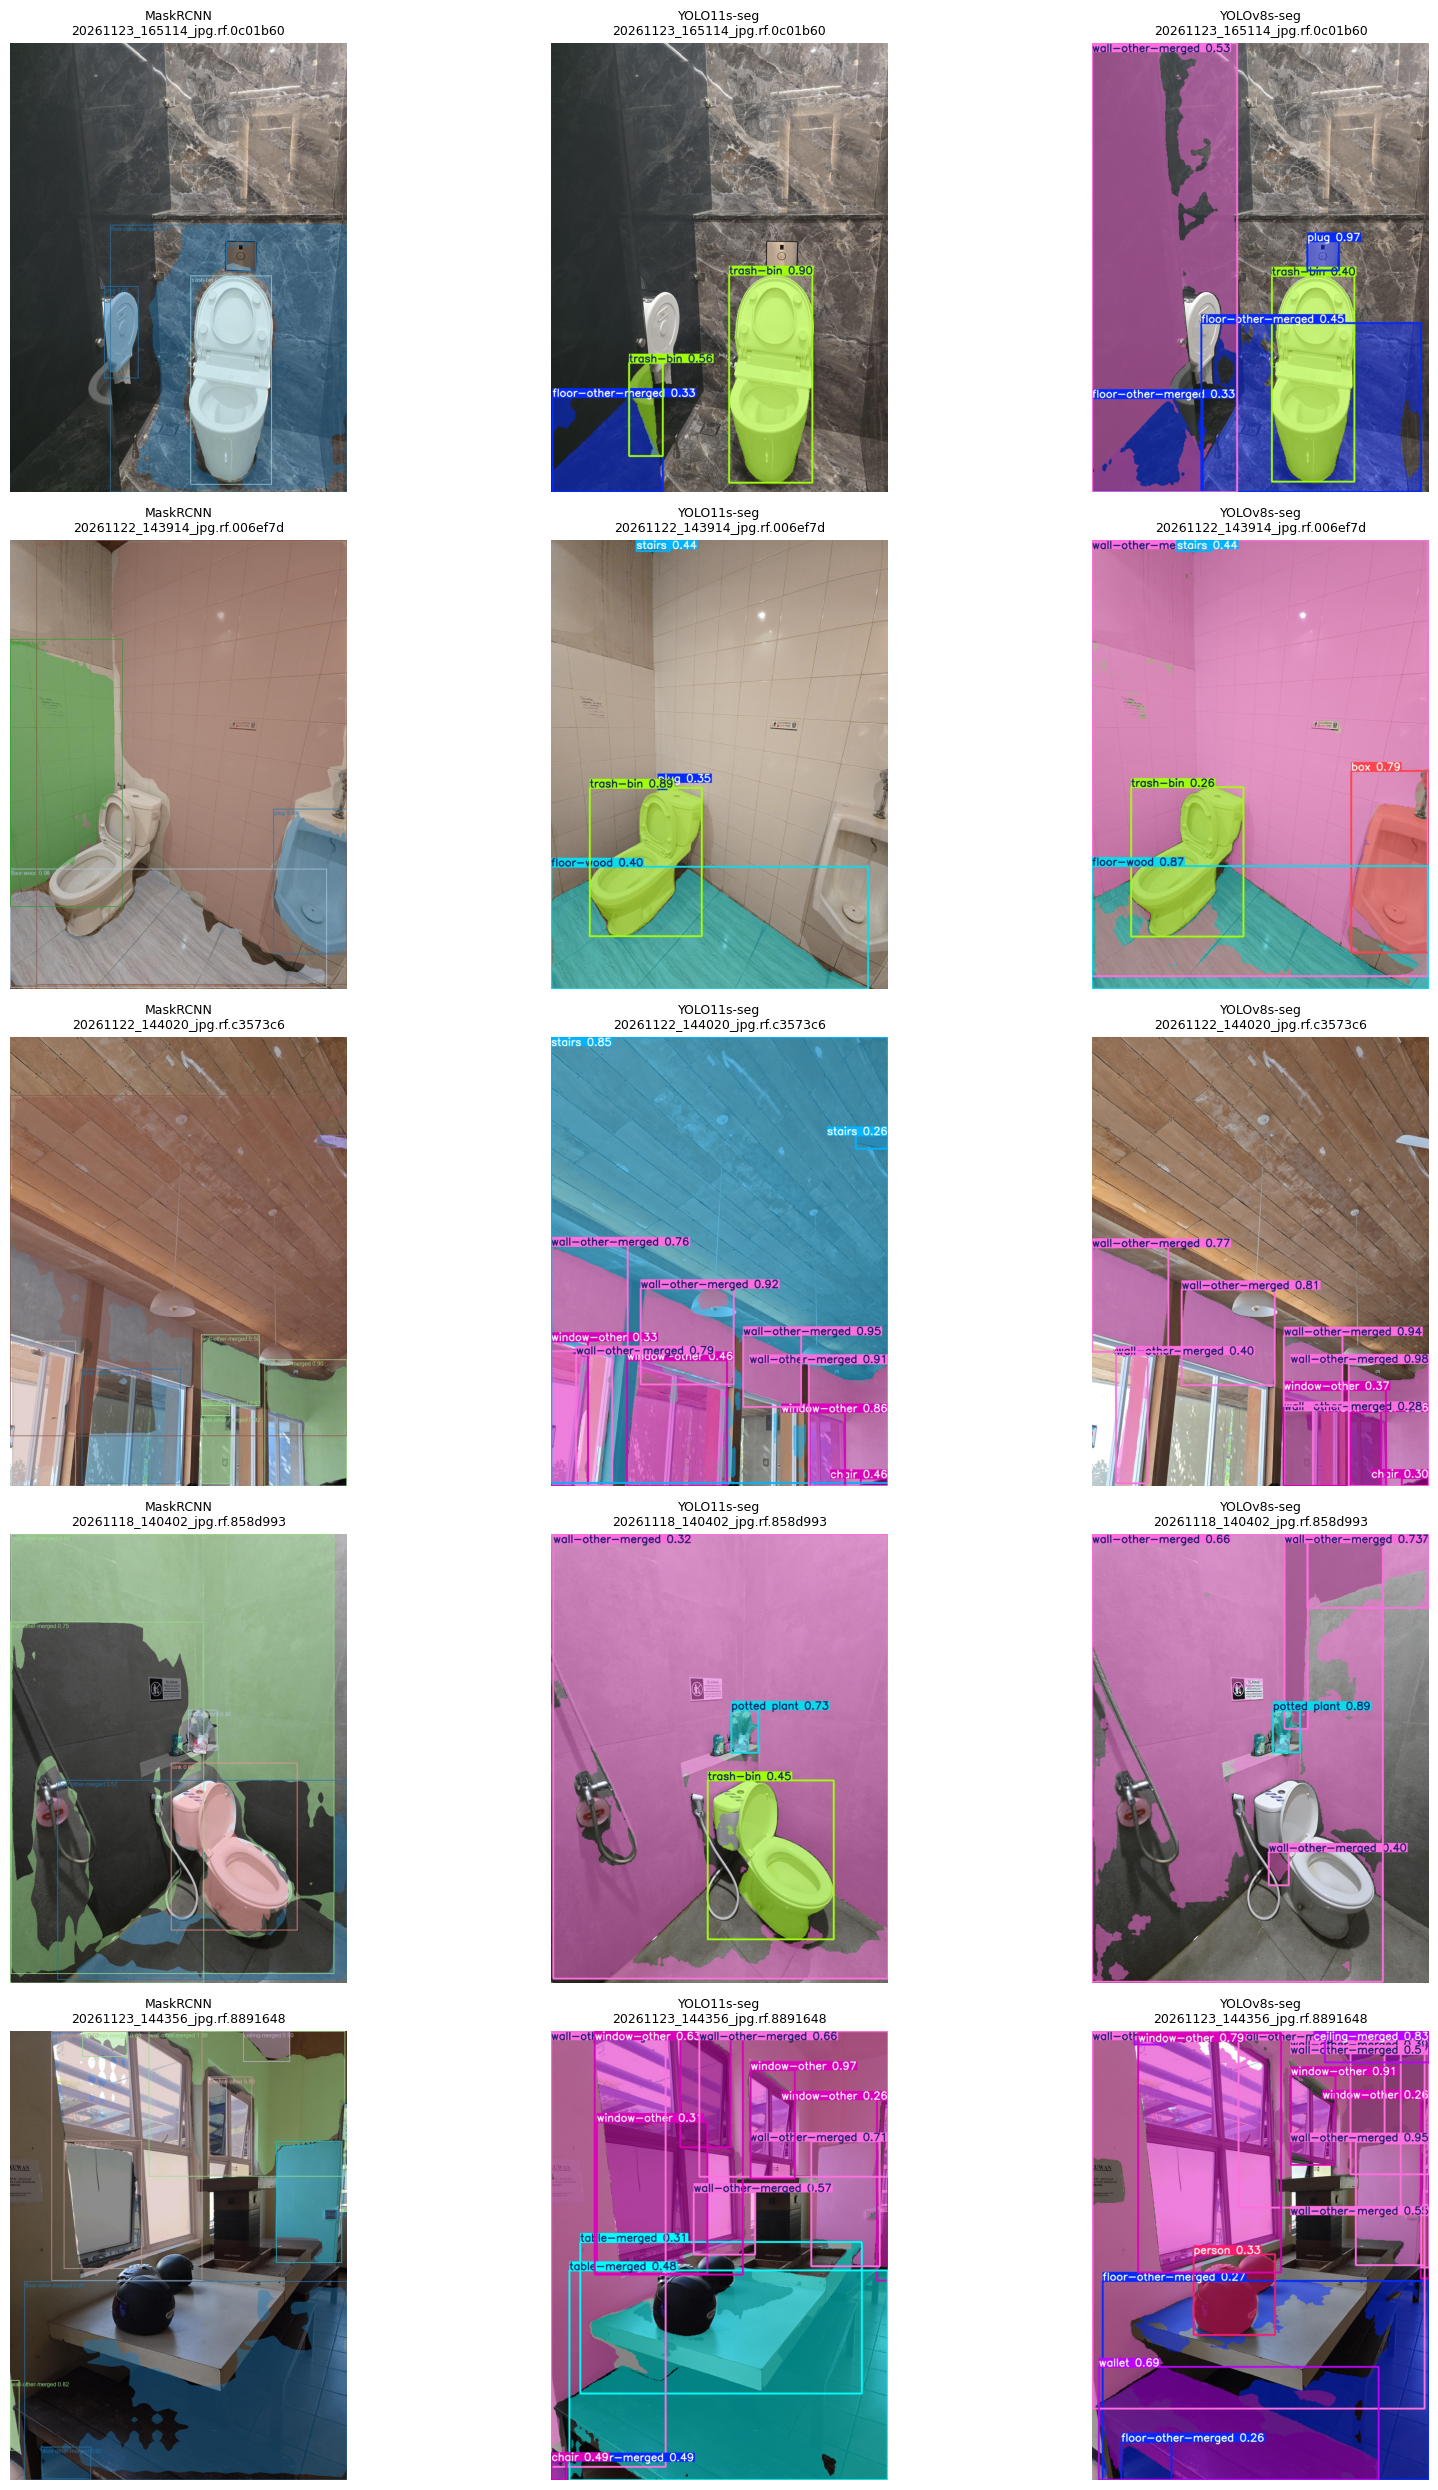


0: 640x480 1 floor-other-merged, 2 trash-bins, 20.8ms
1: 640x480 1 floor-wood, 1 stairs, 1 trash-bin, 20.8ms
2: 640x480 1 chair, 1 door-stuff, 2 stairss, 6 wall-other-mergeds, 2 window-others, 20.8ms
3: 640x480 1 floor-other-merged, 1 plug, 1 potted plant, 1 wall-other-merged, 20.8ms
4: 640x480 1 chair, 1 floor-wood, 1 table-merged, 5 wall-other-mergeds, 3 window-others, 20.8ms
Speed: 1.6ms preprocess, 20.8ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /kaggle/working/CV_Testing/eksperimen_gagal/640_proto

0: 640x480 1 floor-other-merged, 2 trash-bins, 13.8ms
1: 640x480 1 floor-wood, 1 stairs, 1 trash-bin, 13.8ms
2: 640x480 1 chair, 1 door-stuff, 2 stairss, 6 wall-other-mergeds, 2 window-others, 13.8ms
3: 640x480 1 floor-other-merged, 1 plug, 1 potted plant, 1 wall-other-merged, 13.8ms
4: 640x480 1 chair, 1 floor-wood, 1 table-merged, 5 wall-other-mergeds, 3 window-others, 13.8ms
Speed: 1.7ms preprocess, 13.8ms inference, 2.4ms postprocess per ima

,imgsz,mAP50-95 HP,mAP50 HP
0,640,0.122549,0.192728
1,960,0.126503,0.188937


In [8]:
from torchvision.utils import draw_segmentation_masks, draw_bounding_boxes

PRED_DIR = f"{ROOT}/prediksi_hp"
FONT = next(iter(glob.glob("/usr/share/fonts/**/DejaVuSans.ttf", recursive=True)
                 + glob.glob(os.path.expanduser("~/.config/Ultralytics/*.ttf"))), None)
COLORS = [tuple(int(255 * c) for c in plt.cm.tab20(i % 20)[:3]) for i in range(len(NAMES))]

def draw_mrcnn(img, out, thr=0.5):
    keep = out["scores"] > thr
    vis = (img * 255).byte()
    if keep.sum() == 0:
        return vis
    labels, scores = out["labels"][keep].cpu().tolist(), out["scores"][keep].cpu().tolist()
    cols = [COLORS[l - 1] for l in labels]
    vis = draw_segmentation_masks(vis, (out["masks"][keep, 0] > 0.5).cpu(), alpha=0.45, colors=cols)
    return draw_bounding_boxes(vis, out["boxes"][keep].cpu(), labels=[f"{NAMES[l - 1]} {s:.2f}" for l, s in zip(labels, scores)],
                               colors=cols, width=2, font=FONT, font_size=max(14, img.shape[-1] // 60))

def save_predictions():
    imgs = sorted(glob.glob(f"{OWN_ROOT}/test/images/*"))
    for n, w in YOLO_MAIN.items():
        if w:
            YOLO(w).predict(imgs, imgsz=IMGSZ, device=DEVICE, save=True, project=PRED_DIR, name=n, exist_ok=True, verbose=False)
    if MRCNN:
        model = load_mrcnn(MRCNN).eval()
        os.makedirs(f"{PRED_DIR}/MaskRCNN", exist_ok=True)
        for p in imgs:
            img = TF.to_tensor(Image.open(p).convert("RGB"))
            with torch.no_grad():
                out = model([img.to(DEV)])[0]
            TF.to_pil_image(draw_mrcnn(img, out)).save(f"{PRED_DIR}/MaskRCNN/{os.path.basename(p)}")
        del model
        torch.cuda.empty_cache()

def yolo_preds(weights, ds):
    m, res = YOLO(weights), []
    for iid in ds.ids:
        r = m.predict(f"{ds.root}/{ds.coco.imgs[iid]['file_name']}", imgsz=IMGSZ, device=DEVICE, retina_masks=True, verbose=False)[0]
        if r.masks is None:
            continue
        for mk, c, sc in zip(r.masks.data.cpu().numpy() > 0.5, r.boxes.cls.tolist(), r.boxes.conf.tolist()):
            res.append({"image_id": iid, "category_id": int(c) + 1, "segmentation": to_rle(mk), "score": sc})
    return res

def per_image_ap(ds, res):
    dt = ds.coco.loadRes(res) if res else None
    out = {}
    for iid in ds.ids:
        if not ds.coco.getAnnIds(imgIds=iid):
            continue
        if dt is None:
            out[iid] = 0.0; continue
        with contextlib.redirect_stdout(io.StringIO()):
            E = COCOeval(ds.coco, dt, "segm")
            E.params.imgIds = [iid]
            E.evaluate(); E.accumulate(); E.summarize()
        out[iid] = max(float(E.stats[0]), 0.0)
    return out

def failure_table():
    # AP mask per foto HP untuk ketiga model; 5 foto dengan rata-rata terendah (minimal 3 objek) = foto gagal
    global FAIL_IMAGES
    ds = CocoSeg(OWN_COCO_JSON, own_coco.location)
    cols = {n: per_image_ap(ds, yolo_preds(w, ds)) for n, w in YOLO_MAIN.items() if w}
    if MRCNN:
        model = load_mrcnn(MRCNN)
        cols["Mask R-CNN"] = per_image_ap(ds, mrcnn_preds(model, ds))
        del model; torch.cuda.empty_cache()
    df = pd.DataFrame(cols)
    df["rata-rata"] = df.mean(axis=1)
    df["objek GT"] = [len(ds.coco.getAnnIds(imgIds=i)) for i in df.index]
    df["kelas GT"] = [", ".join(sorted({NAMES[a["category_id"] - 1] for a in ds.coco.loadAnns(ds.coco.getAnnIds(imgIds=i))}))
                      for i in df.index]
    yolo_name = {norm_stem(q): os.path.basename(q) for q in glob.glob(f"{OWN_ROOT}/test/images/*")}
    df.index = [yolo_name.get(norm_stem(ds.coco.imgs[i]["file_name"]), ds.coco.imgs[i]["file_name"]) for i in df.index]
    df = df.sort_values("rata-rata").round(3)
    df.to_csv(f"{ROOT}/ap_per_foto_hp.csv")
    if not FAIL_IMAGES:
        FAIL_IMAGES = list(df[df["objek GT"] >= 3].index[:5])
    print("AP mask per foto HP (terendah di atas). Foto gagal yang dipilih:", FAIL_IMAGES)
    display(df)

def show_gallery(files=None, n=6):
    models = sorted(d for d in os.listdir(PRED_DIR) if os.path.isdir(f"{PRED_DIR}/{d}"))
    files = files or sorted(os.listdir(f"{PRED_DIR}/{models[0]}"))[:n]
    fig, axes = plt.subplots(len(files), len(models), figsize=(6 * len(models), 5 * len(files)), squeeze=False)
    for r, f in enumerate(files):
        for c, m in enumerate(models):
            ax = axes[r][c]; ax.axis("off")
            if os.path.exists(f"{PRED_DIR}/{m}/{f}"):
                ax.imshow(Image.open(f"{PRED_DIR}/{m}/{f}"))
            ax.set_title(f"{m}\n{f[:30]}", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{ROOT}/galeri_prediksi.png", dpi=70); plt.show()

def failure_experiment():
    w = YOLO_MAIN["YOLO11s-seg"]
    paths = [f"{OWN_ROOT}/test/images/{f}" for f in FAIL_IMAGES]
    if paths:
        for tag, kw in {"640_proto": dict(imgsz=640), "640_retina": dict(imgsz=640, retina_masks=True),
                        "960_retina": dict(imgsz=960, retina_masks=True)}.items():
            YOLO(w).predict(paths, device=DEVICE, save=True, project=f"{ROOT}/eksperimen_gagal", name=tag, exist_ok=True, **kw)
    df = pd.DataFrame([(s, *eval_yolo(w, OWN_YAML, f"exp_imgsz{s}", imgsz=s)) for s in [640, 960]],
                      columns=["imgsz", "mAP50-95 HP", "mAP50 HP"])
    df.to_csv(f"{ROOT}/eksperimen_gagal.csv", index=False); display(df)

if HAS_OWN:
    stage("prediksi HP", save_predictions)
    stage("AP per foto", failure_table)
    stage("galeri prediksi", show_gallery, FAIL_IMAGES or None)
    stage("eksperimen kegagalan", failure_experiment)

## 7. EXIF foto HP

In [9]:
def read_exif():
    from PIL import ExifTags
    from pillow_heif import register_heif_opener
    register_heif_opener()
    src = get_originals()
    used = {norm_stem(p) for p in glob.glob(f"{OWN_ROOT}/test/images/*")} if HAS_OWN else None
    tag_id = {v: k for k, v in ExifTags.TAGS.items()}
    rows, skipped = [], []
    for p in sorted(glob.glob(f"{src}/**/*.*", recursive=True)):
        if used is not None and norm_stem(p) not in used:
            skipped.append(os.path.basename(p)); continue
        try:
            im = Image.open(p)
        except Exception:
            continue
        exif = im.getexif(); sub = exif.get_ifd(0x8769)
        rows.append({"file": os.path.basename(p), "ukuran": f"{im.width}x{im.height}",
                     "merk": exif.get(tag_id["Make"]), "model HP": exif.get(tag_id["Model"]),
                     "waktu ambil": sub.get(tag_id["DateTimeOriginal"]), "ISO": sub.get(tag_id["ISOSpeedRatings"]),
                     "exposure": str(sub.get(tag_id["ExposureTime"]))})
    df = pd.DataFrame(rows); df.to_csv(f"{ROOT}/exif_foto_hp.csv", index=False)
    print(f"{len(df)} foto test set HP dengan EXIF (dari {src}); tidak dipakai di test set: {skipped}")
    if used is not None:
        missing = sorted(used - {norm_stem(f) for f in df["file"]}) if len(df) else sorted(used)
        print("Foto test set yang tidak ditemukan di folder foto asli:", missing or "tidak ada")
    display(df)

stage("exif", read_exif)

44 foto test set HP dengan EXIF (dari /tmp/foto_hp); tidak dipakai di test set: ['20261123_141201.jpg', '20261123_142814.jpg', '20261123_165108.jpg']
Foto test set yang tidak ditemukan di folder foto asli: tidak ada


,file,ukuran,merk,model HP,waktu ambil,ISO,exposure
0,20261118_134143.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:18 13:41:43,200,0.005567099
1,20261118_134154.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:18 13:41:54,800,0.009991324
2,20261118_134158.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:18 13:41:58,160,0.009991324
3,20261118_134224.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:18 13:42:23,400,0.009991324
4,20261118_134820.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:18 13:48:20,1000,0.009991324
5,20261118_140257.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:18 14:02:57,1250,0.009991324
6,20261118_140402.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:18 14:04:02,1000,0.019982648
7,20261121_092205.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:21 09:22:05,500,0.019982648
8,20261121_125016.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:21 12:50:17,1600,0.009991324
9,20261121_131529.jpg,4000x3000,samsung,Galaxy S24 Ultra,2026:11:21 13:15:29,1600,0.009991324


## 8. Ringkasan

In [10]:
print("Waktu GPU:"); display(pd.read_csv(GPU_LOG)) if os.path.exists(GPU_LOG) else print("-")
print(open(ERR_LOG).read() if os.path.exists(ERR_LOG) else "Tidak ada tahap yang gagal.")

Waktu GPU:
-
Tidak ada tahap yang gagal.
